**Healthcare Data Visualization**

In this notebook we will create charts and graphs from the cleaned healthcare dataset to understand healthcare trends and patterns.

**Import Libraries**

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

**Load the cleaned dataset**

In [5]:
df = pd.read_csv('/content/healthcare_dataset_cleaned.csv')
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length_of_Stay
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,15
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,30
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,20


In [6]:
# check the shape of the dataset
df.shape

(54966, 16)

In [7]:
df.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results', 'Length_of_Stay'],
      dtype='object')

**1. Disease Distribution**

In [8]:
# count the number of patients for each disease
disease_counts = df['Medical Condition'].value_counts()
disease_counts

,count
Medical Condition,
Arthritis,9218
Diabetes,9216
Hypertension,9151
Obesity,9146
Cancer,9140
Asthma,9095


**Bar Chart - Disease Distribution**

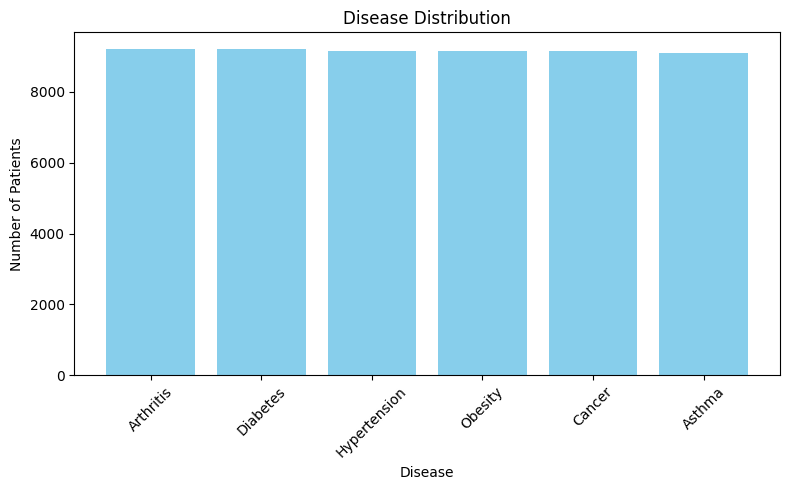

In [9]:
plt.figure(figsize=(8, 5))
plt.bar(disease_counts.index, disease_counts.values, color='skyblue')
plt.xlabel('Disease')
plt.ylabel('Number of Patients')
plt.title('Disease Distribution')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Pie Chart - Disease Distribution**

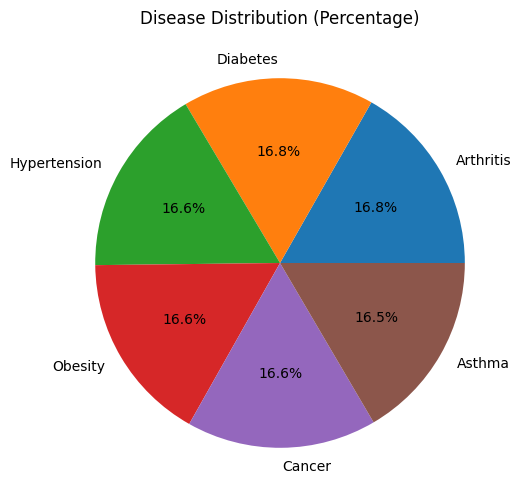

In [10]:
plt.figure(figsize=(6, 6))
plt.pie(disease_counts.values, labels=disease_counts.index, autopct='%1.1f%%')
plt.title('Disease Distribution (Percentage)')
plt.show()

**2. Age Distribution**

In [11]:
# basic age statistics
print("Average Age:", round(df['Age'].mean(), 2))
print("Minimum Age:", df['Age'].min())
print("Maximum Age:", df['Age'].max())

Average Age: 51.54
Minimum Age: 13
Maximum Age: 89


**Histogram - Age Distribution**

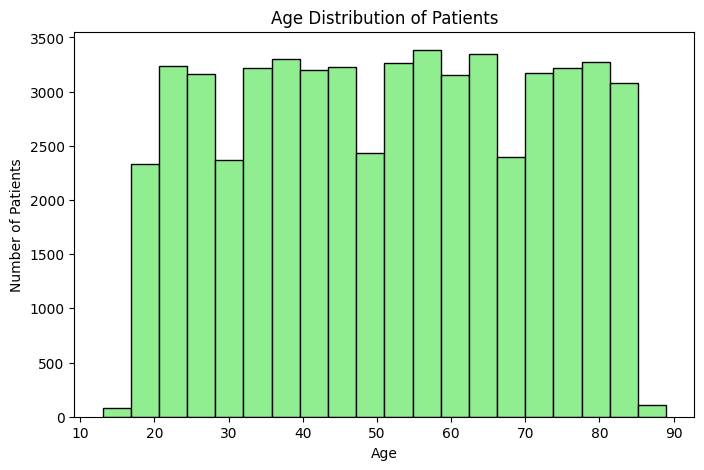

In [12]:
plt.figure(figsize=(8, 5))
plt.hist(df['Age'], bins=20, color='lightgreen', edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Number of Patients')
plt.title('Age Distribution of Patients')
plt.show()

**Age Distribution with Average Line**

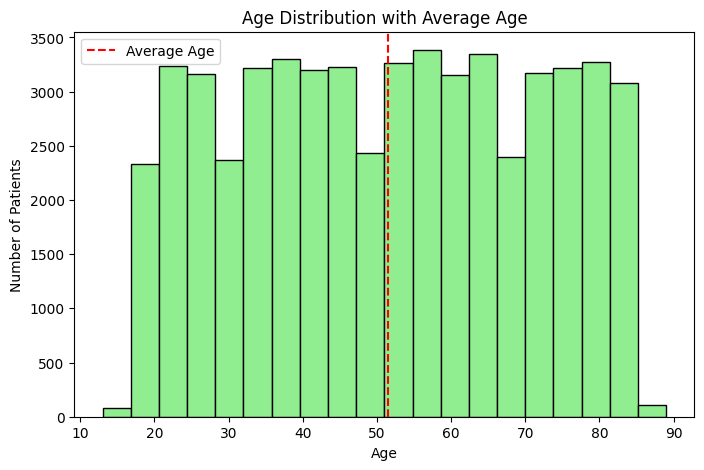

In [13]:
# same histogram but with a line showing average age
plt.figure(figsize=(8, 5))
plt.hist(df['Age'], bins=20, color='lightgreen', edgecolor='black')
plt.axvline(df['Age'].mean(), color='red', linestyle='--', label='Average Age')
plt.xlabel('Age')
plt.ylabel('Number of Patients')
plt.title('Age Distribution with Average Age')
plt.legend()
plt.show()

**Age Distribution by Disease**

In [14]:
# see the average age for each disease
avg_age_by_disease = df.groupby('Medical Condition')['Age'].mean().round(2)
avg_age_by_disease

,Age
Medical Condition,
Arthritis,51.54
Asthma,51.60
Cancer,51.54
Diabetes,51.58
Hypertension,51.72
Obesity,51.23


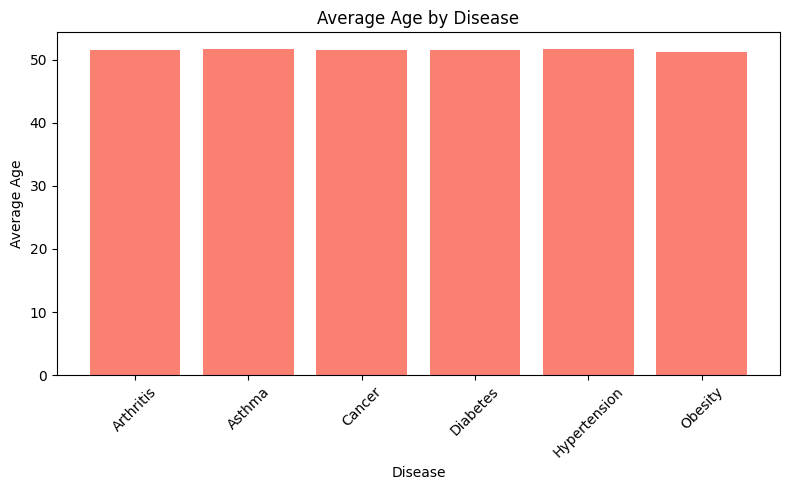

In [15]:
plt.figure(figsize=(8, 5))
plt.bar(avg_age_by_disease.index, avg_age_by_disease.values, color='salmon')
plt.xlabel('Disease')
plt.ylabel('Average Age')
plt.title('Average Age by Disease')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**3. Gender Ratio**

In [16]:
# count male and female patients
gender_counts = df['Gender'].value_counts()
gender_counts

,count
Gender,
Male,27496
Female,27470


**Pie Chart - Gender Ratio**

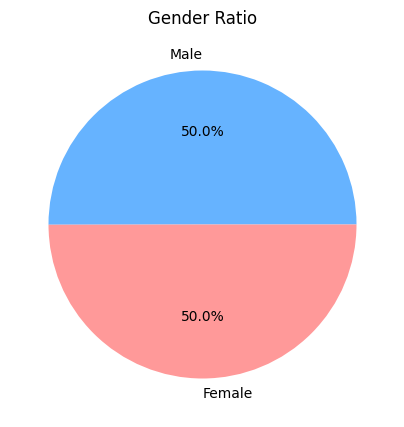

In [17]:
plt.figure(figsize=(5, 5))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%', colors=['#66b3ff', '#ff9999'])
plt.title('Gender Ratio')
plt.show()

**Bar Chart - Gender Ratio**

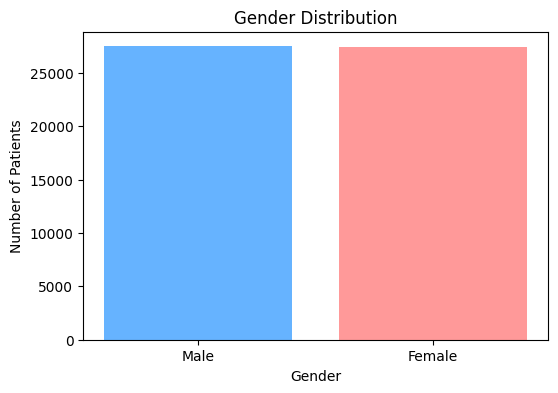

In [18]:
plt.figure(figsize=(6, 4))
plt.bar(gender_counts.index, gender_counts.values, color=['#66b3ff', '#ff9999'])
plt.xlabel('Gender')
plt.ylabel('Number of Patients')
plt.title('Gender Distribution')
plt.show()

**Gender wise Disease Distribution**

In [19]:
# count of diseases for each gender
gender_disease = df.groupby(['Gender', 'Medical Condition']).size().unstack()
gender_disease

Medical Condition,Arthritis,Asthma,Cancer,Diabetes,Hypertension,Obesity
Gender,,,,,,
Female,4642,4511,4566,4609,4569,4573
Male,4576,4584,4574,4607,4582,4573


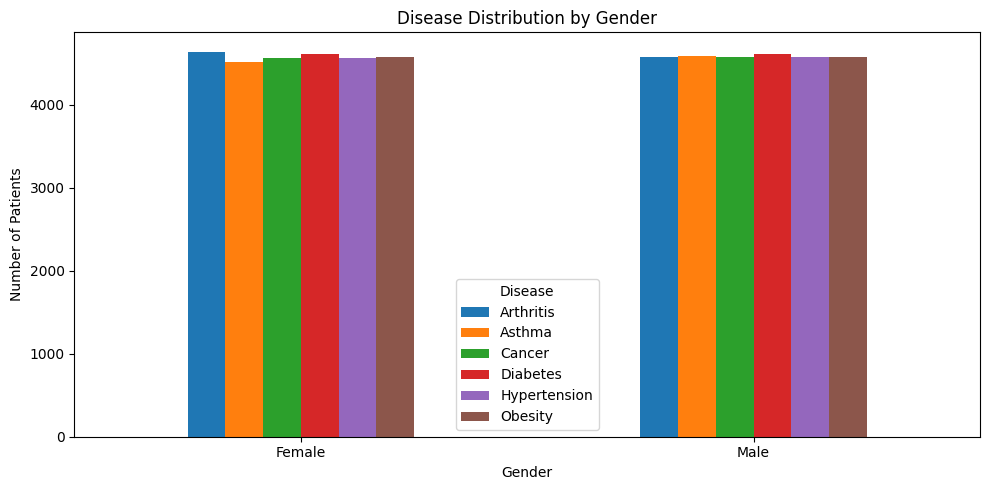

In [20]:
gender_disease.plot(kind='bar', figsize=(10, 5))
plt.xlabel('Gender')
plt.ylabel('Number of Patients')
plt.title('Disease Distribution by Gender')
plt.xticks(rotation=0)
plt.legend(title='Disease')
plt.tight_layout()
plt.show()

**4. Medication Usage**

In [21]:
# count how many times each medication was prescribed
med_counts = df['Medication'].value_counts()
med_counts

,count
Medication,
Lipitor,11038
Ibuprofen,11023
Aspirin,10984
Paracetamol,10965
Penicillin,10956


**Bar Chart - Medication Usage**

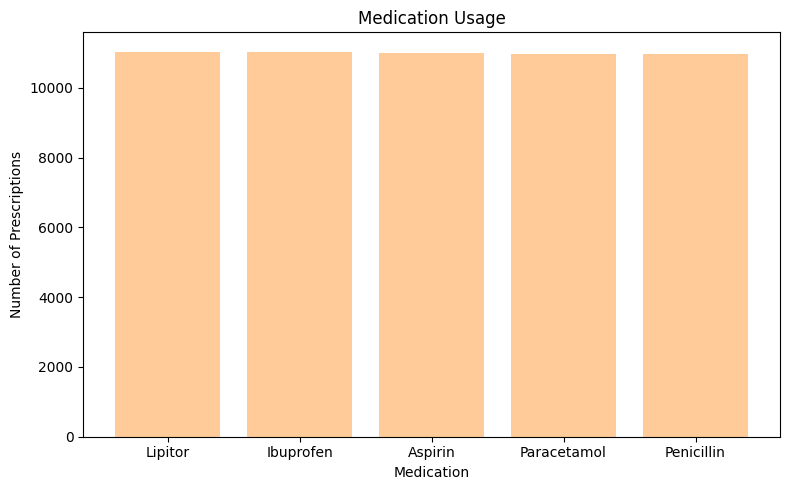

In [22]:
plt.figure(figsize=(8, 5))
plt.bar(med_counts.index, med_counts.values, color='#ffcc99')
plt.xlabel('Medication')
plt.ylabel('Number of Prescriptions')
plt.title('Medication Usage')
plt.tight_layout()
plt.show()

**Pie Chart - Medication Usage**

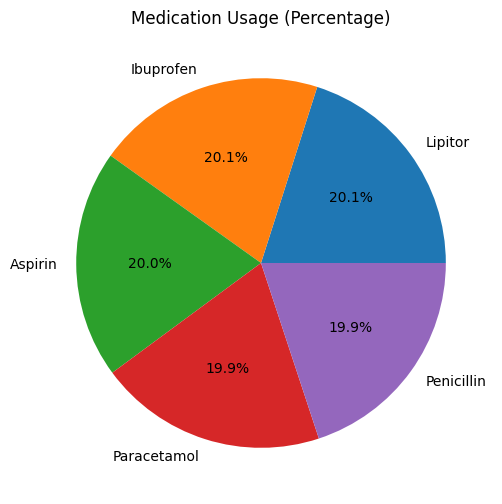

In [23]:
plt.figure(figsize=(6, 6))
plt.pie(med_counts.values, labels=med_counts.index, autopct='%1.1f%%')
plt.title('Medication Usage (Percentage)')
plt.show()

**Medication Usage by Disease**

In [24]:
# see which medication is used for which disease
disease_med = df.groupby(['Medical Condition', 'Medication']).size().unstack()
disease_med

Medication,Aspirin,Ibuprofen,Lipitor,Paracetamol,Penicillin
Medical Condition,,,,,
Arthritis,1901,1805,1810,1858,1844
Asthma,1781,1802,1814,1870,1828
Cancer,1768,1862,1904,1829,1777
Diabetes,1836,1846,1875,1794,1865
Hypertension,1845,1874,1823,1839,1770
Obesity,1853,1834,1812,1775,1872


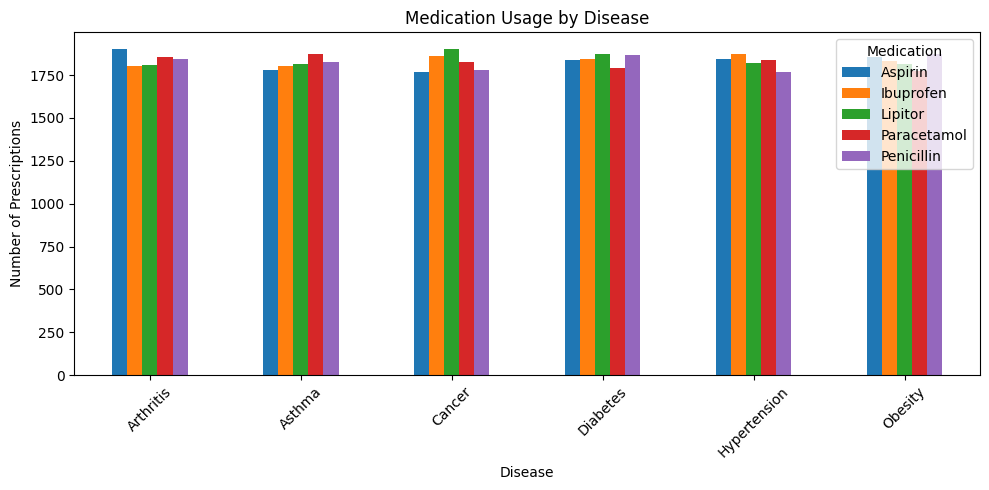

In [25]:
disease_med.plot(kind='bar', figsize=(10, 5))
plt.xlabel('Disease')
plt.ylabel('Number of Prescriptions')
plt.title('Medication Usage by Disease')
plt.xticks(rotation=45)
plt.legend(title='Medication')
plt.tight_layout()
plt.show()